# Exercise 1: Multi-Layer Perceptron (MLP) on CIFAR-10

This notebook implements, trains, and evaluates a 3-layer Multi-Layer Perceptron (`CIFAR10_MLP`) on the CIFAR-10 dataset using PyTorch.

## 1. Setup & Reproducibility

Import required libraries, fix random seeds (`42`) for reproducibility, detect the CUDA device (RTX 4050), and load the CIFAR-10 DataLoaders from `../src/data_loader.py`.

In [1]:
import os
import sys
import random

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Detect GPU (CUDA) availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version: {torch.__version__}")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU Detected: {torch.cuda.get_device_name(0)}")

# Add ../src to sys.path so we can import get_cifar10_loaders
src_path = os.path.abspath("../src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

from data_loader import get_cifar10_loaders

# Load train (45,000), validation (5,000), and test (10,000) DataLoaders
BATCH_SIZE = 64
train_loader, val_loader, test_loader = get_cifar10_loaders(
    batch_size=BATCH_SIZE,
    val_split=0.1,
    seed=SEED,
)

print(f"Train samples: {len(train_loader.dataset)} ({len(train_loader)} batches)")
print(f"Val samples:   {len(val_loader.dataset)} ({len(val_loader)} batches)")
print(f"Test samples:  {len(test_loader.dataset)} ({len(test_loader)} batches)")

Matplotlib is building the font cache; this may take a moment.


PyTorch Version: 2.6.0+cu124
Using device: cuda
GPU Detected: NVIDIA GeForce RTX 4050 Laptop GPU


  0%|                                               | 0.00/170M [00:00<?, ?B/s]

  0%|                                      | 32.8k/170M [00:00<57:59, 49.0kB/s]

  0%|                                       | 98.3k/170M [00:01<26:59, 105kB/s]

  0%|                                        | 164k/170M [00:01<20:21, 139kB/s]

... (682 outputs left out)

100%|██████████████████████████████████████▉| 170M/170M [01:52<00:00, 1.64MB/s]

100%|██████████████████████████████████████▉| 170M/170M [01:52<00:00, 1.61MB/s]

100%|███████████████████████████████████████| 170M/170M [01:52<00:00, 1.52MB/s]

Train samples: 45000 (704 batches)
Val samples:   5000 (79 batches)
Test samples:  10000 (157 batches)


## 2. MLP Architecture

Define `CIFAR10_MLP` with **exactly three trainable `nn.Linear` layers**:
- Flatten `3 x 32 x 32` (`3072`) input
- `Linear(3072 -> 512)` + `ReLU`
- `Linear(512 -> 256)` + `ReLU`
- `Linear(256 -> 10)` output logits

In [2]:
class CIFAR10_MLP(nn.Module):
    """Three-layer Multi-Layer Perceptron for CIFAR-10 image classification."""

    def __init__(self, num_classes: int = 10) -> None:
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),              # (B, 3, 32, 32) -> (B, 3072)
            nn.Linear(3072, 512),      # Trainable Linear layer 1
            nn.ReLU(),
            nn.Linear(512, 256),       # Trainable Linear layer 2
            nn.ReLU(),
            nn.Linear(256, num_classes)  # Trainable Linear layer 3
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)


# Instantiate model and move to target device
model = CIFAR10_MLP(num_classes=10).to(device)

# Print model summary and total trainable parameter count
print(model)
total_trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
print(f"\nTotal trainable parameters: {total_trainable_params:,}")

CIFAR10_MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)

Total trainable parameters: 1,707,274


## 3. Training & Validation Loop

Train for 20 epochs using `nn.CrossEntropyLoss()` and `torch.optim.Adam(lr=0.001)`. Track training/validation loss and accuracy per epoch, and save the weights achieving the highest validation accuracy to `../models/mlp_best.pth`.

In [3]:
# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

NUM_EPOCHS = 20
MODEL_DIR = "../models"
BEST_MODEL_PATH = os.path.join(MODEL_DIR, "mlp_best.pth")
os.makedirs(MODEL_DIR, exist_ok=True)

# History containers
train_losses, val_losses = [], []
train_accs, val_accs = [], []
best_val_acc = 0.0

for epoch in range(1, NUM_EPOCHS + 1):
    # --- Training Phase ---
    model.train()
    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = running_train_loss / train_total
    epoch_train_acc = 100.0 * train_correct / train_total

    # --- Validation Phase ---
    model.eval()
    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = running_val_loss / val_total
    epoch_val_acc = 100.0 * val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accs.append(epoch_train_acc)
    val_accs.append(epoch_val_acc)

    # Save best model checkpoint based on validation accuracy
    saved_marker = ""
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        saved_marker = " [Saved Best]"

    print(
        f"Epoch [{epoch:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | "
        f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}%{saved_marker}"
    )

print(f"\nTraining complete. Best Validation Accuracy: {best_val_acc:.2f}%")

Epoch [01/20] | Train Loss: 1.6649, Train Acc: 40.83% | Val Loss: 1.5770, Val Acc: 45.60% [Saved Best]


Epoch [02/20] | Train Loss: 1.4729, Train Acc: 47.84% | Val Loss: 1.4748, Val Acc: 47.42% [Saved Best]


Epoch [03/20] | Train Loss: 1.3692, Train Acc: 51.49% | Val Loss: 1.4237, Val Acc: 50.00% [Saved Best]


Epoch [04/20] | Train Loss: 1.2857, Train Acc: 54.59% | Val Loss: 1.4405, Val Acc: 50.16% [Saved Best]


Epoch [05/20] | Train Loss: 1.2175, Train Acc: 56.73% | Val Loss: 1.4162, Val Acc: 51.42% [Saved Best]


Epoch [06/20] | Train Loss: 1.1517, Train Acc: 58.94% | Val Loss: 1.4030, Val Acc: 52.54% [Saved Best]


... (10 outputs left out)

Epoch [17/20] | Train Loss: 0.5946, Train Acc: 78.40% | Val Loss: 2.0659, Val Acc: 50.60%


Epoch [18/20] | Train Loss: 0.5815, Train Acc: 79.14% | Val Loss: 2.1094, Val Acc: 49.62%


Epoch [19/20] | Train Loss: 0.5447, Train Acc: 80.52% | Val Loss: 2.2038, Val Acc: 50.64%


Epoch [20/20] | Train Loss: 0.5091, Train Acc: 81.79% | Val Loss: 2.2960, Val Acc: 50.42%

Training complete. Best Validation Accuracy: 52.60%


## 4. Test Evaluation

Load the best saved weights from `../models/mlp_best.pth`, evaluate final accuracy on the unseen 10,000-image test set, and print a per-class `classification_report`.

In [4]:
CIFAR10_CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# Load the best model checkpoint
best_model = CIFAR10_MLP(num_classes=10).to(device)
best_model.load_state_dict(
    torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True)
)
best_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        outputs = best_model(images)
        _, preds = torch.max(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
test_accuracy = 100.0 * (all_preds == all_labels).sum() / len(all_labels)

print(f"Final Test Accuracy (10,000 images): {test_accuracy:.2f}%\n")
print("Classification Report:")
print(classification_report(all_labels, all_preds, target_names=CIFAR10_CLASSES, digits=4))

Final Test Accuracy (10,000 images): 52.53%

Classification Report:
              precision    recall  f1-score   support

    airplane     0.6046    0.6300    0.6170      1000
  automobile     0.6027    0.7040    0.6494      1000
        bird     0.4785    0.3450    0.4009      1000
         cat     0.3406    0.3610    0.3505      1000
        deer     0.4933    0.3300    0.3954      1000
         dog     0.3903    0.4360    0.4119      1000
        frog     0.4851    0.6820    0.5669      1000
       horse     0.6124    0.5720    0.5915      1000
        ship     0.6674    0.6480    0.6575      1000
       truck     0.5976    0.5450    0.5701      1000

    accuracy                         0.5253     10000
   macro avg     0.5272    0.5253    0.5211     10000
weighted avg     0.5272    0.5253    0.5211     10000



## 5. Visualisation

Plot side-by-side high-resolution Training vs. Validation Loss and Accuracy curves and save the figure to `../notebooks/ex1_mlp_curves.png`.

Saved learning curves to ../notebooks/ex1_mlp_curves.png


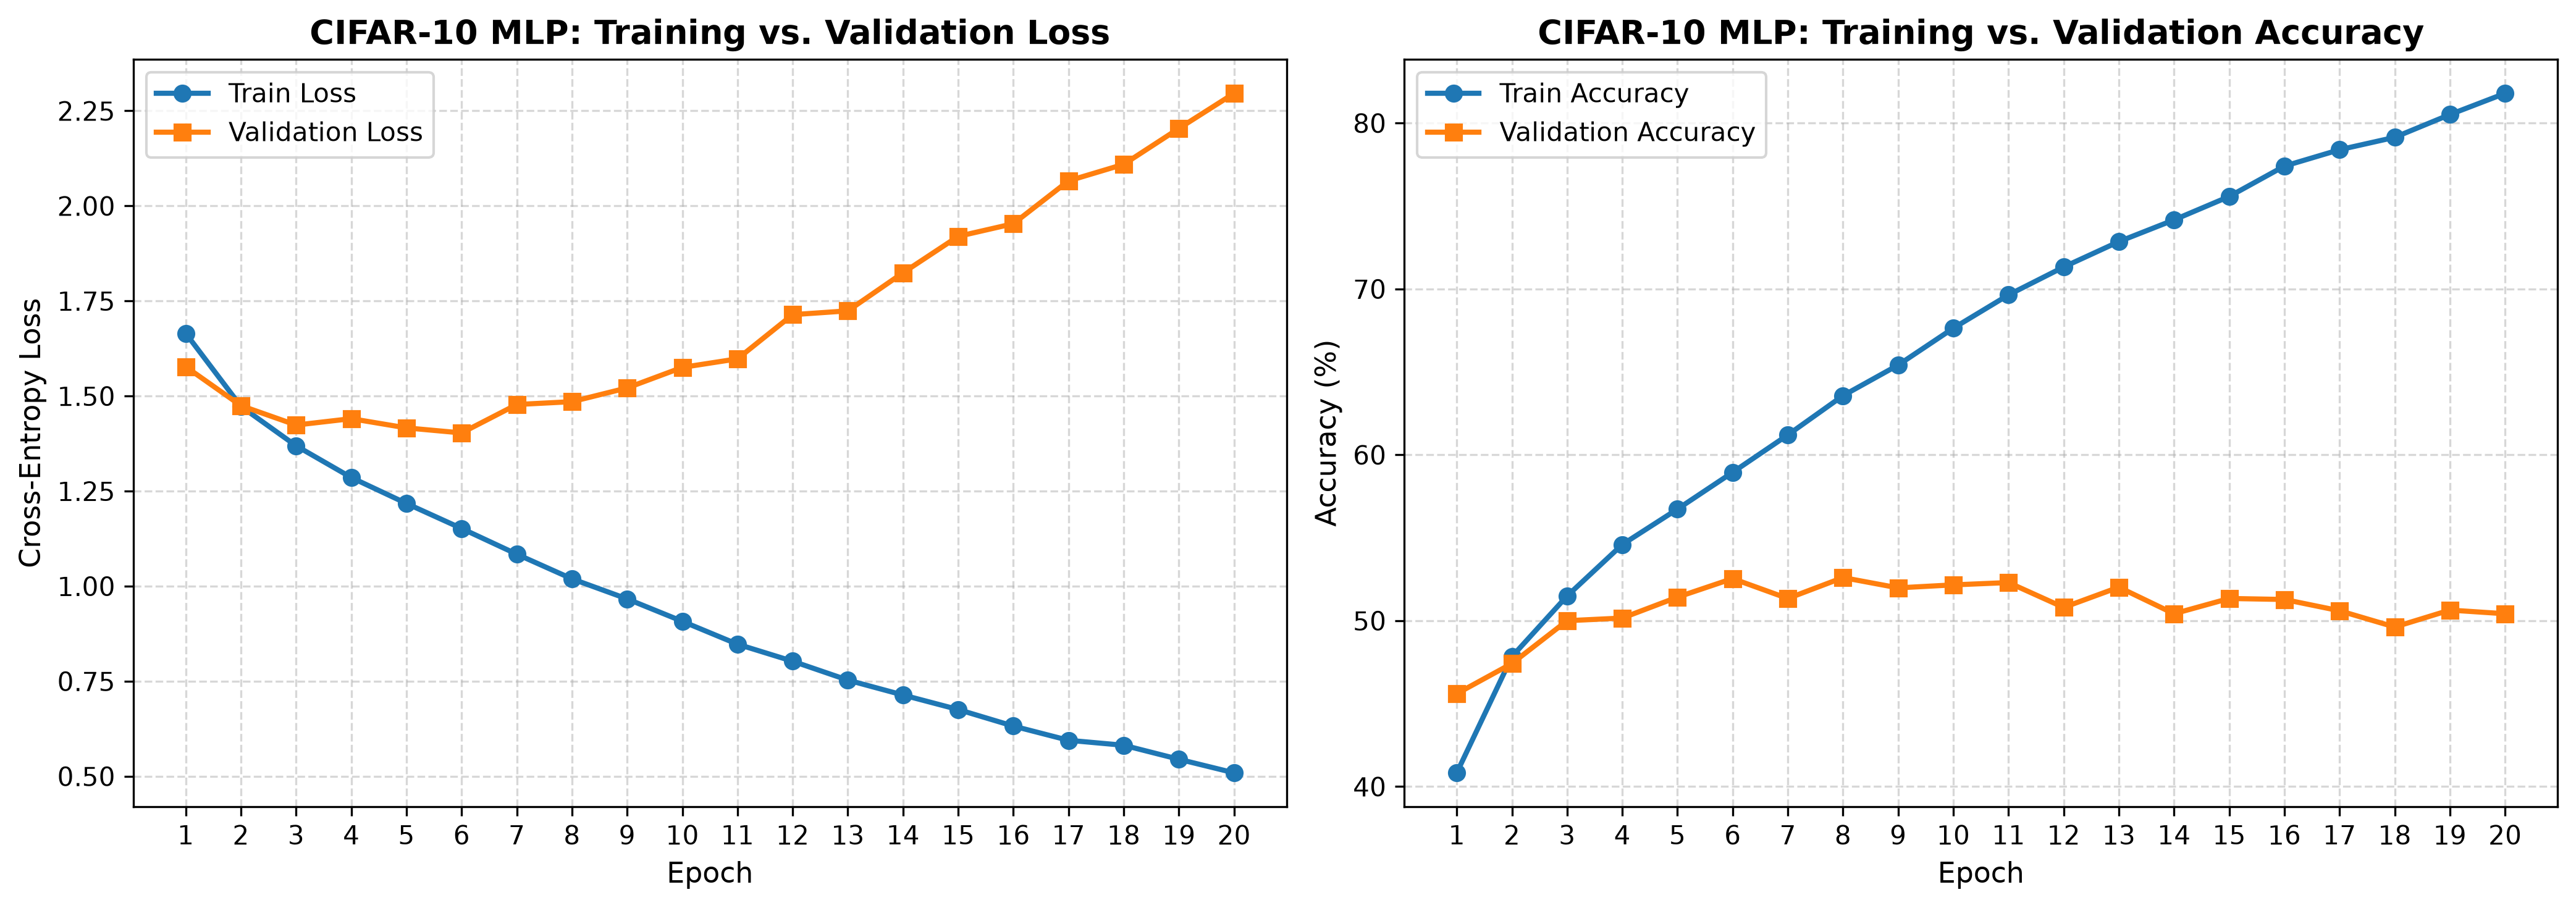

In [5]:
epochs_range = range(1, NUM_EPOCHS + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

# Left subplot: Training vs. Validation Loss
ax1.plot(epochs_range, train_losses, marker="o", linewidth=2, label="Train Loss")
ax1.plot(epochs_range, val_losses, marker="s", linewidth=2, label="Validation Loss")
ax1.set_title("CIFAR-10 MLP: Training vs. Validation Loss", fontsize=13, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Cross-Entropy Loss", fontsize=11)
ax1.set_xticks(epochs_range)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(fontsize=10)

# Right subplot: Training vs. Validation Accuracy
ax2.plot(epochs_range, train_accs, marker="o", linewidth=2, label="Train Accuracy")
ax2.plot(epochs_range, val_accs, marker="s", linewidth=2, label="Validation Accuracy")
ax2.set_title("CIFAR-10 MLP: Training vs. Validation Accuracy", fontsize=13, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Accuracy (%)", fontsize=11)
ax2.set_xticks(epochs_range)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(fontsize=10)

plt.tight_layout()

# Save high-resolution figure
os.makedirs("../notebooks", exist_ok=True)
CURVES_PATH = "../notebooks/ex1_mlp_curves.png"
plt.savefig(CURVES_PATH, dpi=300, bbox_inches="tight")
print(f"Saved learning curves to {CURVES_PATH}")
plt.show()